In [1]:
import sys
from pathlib import Path
raiz = Path.cwd()
while not (raiz / "src").exists() and raiz != raiz.parent:
    raiz = raiz.parent
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
from src.cuantizacion import cargar_modelos, transformar, ESTRATEGIAS

BASE = raiz / "resultados" / "actividad3"
COLS = ["edad", "ingresos", "altura"]
BINS = [5, 10, 25, 50]

In [2]:
r5 = pd.read_csv(BASE / "tablas" / "resultados_5M.csv")
assert len(r5) == 72, len(r5)
assert (r5["n_filas"] == 5_000_000).all()
assert r5["validacion_ok"].all()
assert (r5["bins_reales"] <= r5["bins_solicitados"]).all()
assert r5[["mae", "rmse", "error_max"]].notna().all().all()
print("tabla OK:", r5.shape)
print("NaN por columna (%):", r5.groupby("columna")["pct_nan"].first().to_dict())
print("fuera de rango máx (%):", r5["pct_fuera_rango"].max())
print("RAM máxima del proceso (MB):", r5["rss_MB"].max())
print("bins reales distintos de los solicitados:")
display(r5[r5["bins_reales"] != r5["bins_solicitados"]][
    ["columna", "estrategia", "bins_solicitados", "bins_reales"]].drop_duplicates())

tabla OK: (72, 28)
NaN por columna (%): {'altura': 0.0, 'edad': 0.0, 'ingresos': 0.0}
fuera de rango máx (%): 0.0
RAM máxima del proceso (MB): 673.4
bins reales distintos de los solicitados:


,columna,estrategia,bins_solicitados,bins_reales


In [3]:
df = pd.read_parquet(raiz / "data" / "dataset_5M.parquet", columns=COLS)
for estr in ESTRATEGIAS:
    for k in BINS:
        modelos = cargar_modelos(BASE / "modelos" / "5M" / f"{estr}_{k}.json")
        guardados = pd.read_parquet(BASE / "datos_cuantizados" / "5M" / f"codigos_{estr}_{k}.parquet")
        assert len(guardados) == len(df) == 5_000_000
        for c in COLS:
            assert np.array_equal(transformar(df[c], modelos[c]), guardados[c].to_numpy()), (estr, k, c)
print("OK: los 8 JSON y los 8 parquets del 5M son legibles y reproducen los códigos exactamente")

OK: los 8 JSON y los 8 parquets del 5M son legibles y reproducen los códigos exactamente


In [4]:
r1 = pd.read_csv(BASE / "tablas" / "resultados_1M.csv")

def tiempos(r):
    g = r.groupby(["columna", "estrategia", "bins_solicitados"])
    return pd.DataFrame({
        "t_ajuste_s": g["t_ajuste_s"].first(),
        "t_transformar_s": g["t_transformar_s"].first(),
        "t_reconstruir_s": g["t_reconstruir_s"].mean(),   # media de los 3 representantes
    })

t1, t5 = tiempos(r1), tiempos(r5)
ratio = (t5 / t1).round(2)
print("Tiempos 1M (s)"); display(t1.round(4))
print("Tiempos 5M (s)"); display(t5.round(4))
print("Razón 5M / 1M (se espera cerca de 5)"); display(ratio)
print("Mediana de la razón por estrategia:")
display(ratio.groupby(level="estrategia").median())
print("Tiempo total sumado (s): 1M =", round(t1.sum().sum(), 2), "| 5M =", round(t5.sum().sum(), 2))

Tiempos 1M (s)


t_ajuste_s  t_transformar_s  \
columna  estrategia bins_solicitados                                
altura   cuantiles  5                     0.0556           0.0169   
                    10                    0.0623           0.0241   
                    25                    0.0793           0.0343   
                    50                    0.1085           0.0451   
         uniforme   5                     0.0417           0.0137   
                    10                    0.0444           0.0217   
                    25                    0.0666           0.0325   
                    50                    0.0538           0.0383   
edad     cuantiles  5                     0.0565           0.0167   
                    10                    0.0669           0.0251   
                    25                    0.0831           0.0433   
                    50                    0.1171           0.0365   
         uniforme   5                     0.0551           0.0248   
                    10                    0.0421           0.0238   
                    25                    0.0537           0.0341   
                    50                    0.0651           0.0372   
ingresos cuantiles  5                     0.0562           0.0179   
                    10                    0.0605           0.0251   
                    25                    0.0798           0.0338   
                    50                    0.0945           0.0362   
         uniforme   5                     0.1101           0.0139   
                    10                    0.0380           0.0146   
                    25                    0.0589           0.0336   
                    50                    0.0477           0.0265   

                                      t_reconstruir_s  
columna  estrategia bins_solicitados                   
altura   cuantiles  5                          0.0044  
                    10                         0.0044  
                    25                         0.0055  
                    50                         0.0060  
         uniforme   5                          0.0056  
                    10                         0.0042  
                    25                         0.0044  
                    50                         0.0038  
edad     cuantiles  5                          0.0040  
                    10                         0.0051  
                    25                         0.0044  
                    50                         0.0052  
         uniforme   5                          0.0055  
                    10                         0.0043  
                    25                         0.0048  
                    50                         0.0041  
ingresos cuantiles  5                          0.0040  
                    10                         0.0043  
                    25                         0.0047  
                    50                         0.0073  
         uniforme   5                          0.0055  
                    10                         0.0049  
                    25                         0.0045  
                    50                         0.0038

Tiempos 5M (s)


t_ajuste_s  t_transformar_s  \
columna  estrategia bins_solicitados                                
altura   cuantiles  5                     0.3475           0.0940   
                    10                    0.3718           0.1294   
                    25                    0.5721           0.2561   
                    50                    0.6794           0.3097   
         uniforme   5                     0.1842           0.0656   
                    10                    0.2472           0.1298   
                    25                    0.2917           0.2060   
                    50                    0.3248           0.2157   
edad     cuantiles  5                     0.3508           0.0840   
                    10                    0.4623           0.1255   
                    25                    0.5678           0.2670   
                    50                    0.7147           0.3319   
         uniforme   5                     0.2888           0.0775   
                    10                    0.2347           0.1646   
                    25                    0.3218           0.2015   
                    50                    0.3636           0.2216   
ingresos cuantiles  5                     0.2809           0.0968   
                    10                    0.3514           0.1622   
                    25                    0.5091           0.2071   
                    50                    0.7803           0.3162   
         uniforme   5                     0.2222           0.0470   
                    10                    0.2526           0.0694   
                    25                    0.2076           0.0906   
                    50                    0.2274           0.1282   

                                      t_reconstruir_s  
columna  estrategia bins_solicitados                   
altura   cuantiles  5                          0.0201  
                    10                         0.0191  
                    25                         0.0237  
                    50                         0.0375  
         uniforme   5                          0.0223  
                    10                         0.0204  
                    25                         0.0223  
                    50                         0.0199  
edad     cuantiles  5                          0.0203  
                    10                         0.0188  
                    25                         0.0246  
                    50                         0.0383  
         uniforme   5                          0.0229  
                    10                         0.0224  
                    25                         0.0199  
                    50                         0.0217  
ingresos cuantiles  5                          0.0207  
                    10                         0.0192  
                    25                         0.0231  
                    50                         0.0342  
         uniforme   5                          0.0258  
                    10                         0.0230  
                    25                         0.0187  
                    50                         0.0201

Razón 5M / 1M (se espera cerca de 5)


t_ajuste_s  t_transformar_s  \
columna  estrategia bins_solicitados                                
altura   cuantiles  5                       6.25             5.57   
                    10                      5.97             5.37   
                    25                      7.21             7.46   
                    50                      6.26             6.87   
         uniforme   5                       4.42             4.77   
                    10                      5.57             5.99   
                    25                      4.38             6.34   
                    50                      6.04             5.63   
edad     cuantiles  5                       6.21             5.03   
                    10                      6.91             5.01   
                    25                      6.84             6.17   
                    50                      6.10             9.09   
         uniforme   5                       5.24             3.13   
                    10                      5.58             6.92   
                    25                      5.99             5.91   
                    50                      5.58             5.96   
ingresos cuantiles  5                       5.00             5.41   
                    10                      5.81             6.47   
                    25                      6.38             6.13   
                    50                      8.25             8.74   
         uniforme   5                       2.02             3.39   
                    10                      6.66             4.75   
                    25                      3.53             2.70   
                    50                      4.77             4.84   

                                      t_reconstruir_s  
columna  estrategia bins_solicitados                   
altura   cuantiles  5                            4.58  
                    10                           4.32  
                    25                           4.29  
                    50                           6.19  
         uniforme   5                            3.94  
                    10                           4.84  
                    25                           5.12  
                    50                           5.30  
edad     cuantiles  5                            5.03  
                    10                           3.72  
                    25                           5.63  
                    50                           7.36  
         uniforme   5                            4.17  
                    10                           5.21  
                    25                           4.13  
                    50                           5.32  
ingresos cuantiles  5                            5.12  
                    10                           4.46  
                    25                           4.92  
                    50                           4.69  
         uniforme   5                            4.68  
                    10                           4.72  
                    25                           4.16  
                    50                           5.29

Mediana de la razón por estrategia:


,t_ajuste_s,t_transformar_s,t_reconstruir_s
estrategia,,,
cuantiles,6.255,6.150,4.805
uniforme,5.405,5.235,4.780


Tiempo total sumado (s): 1M = 2.38 | 5M = 13.71


In [5]:
clave = ["columna", "estrategia", "representante", "bins_solicitados"]
m = (r1.set_index(clave)[["mae", "rmse", "error_max"]]
       .join(r5.set_index(clave)[["mae", "rmse", "error_max"]], lsuffix="_1M", rsuffix="_5M"))
m["ratio_mae"] = m["mae_5M"] / m["mae_1M"]
print(m["ratio_mae"].describe().round(4))
display(m["ratio_mae"].groupby(level=["columna", "estrategia"]).mean().round(4))

count    72.0000
mean      1.0620
std       0.0849
min       0.9935
25%       1.0006
50%       1.0225
75%       1.0784
max       1.2880
Name: ratio_mae, dtype: float64


columna   estrategia
altura    cuantiles     1.0096
          uniforme      1.0172
edad      cuantiles     1.0262
          uniforme      1.0493
ingresos  cuantiles     1.0890
          uniforme      1.1806
Name: ratio_mae, dtype: float64

In [6]:
cons = pd.concat([r1, r5], ignore_index=True)
assert len(cons) == 144 and set(cons["dataset"]) == {"1M", "5M"}
assert list(r1.columns) == list(r5.columns)
destino = BASE / "tablas" / "resultados_actividad3.csv"
cons.to_csv(destino, index=False)

# Respaldo: reabrir el archivo recién guardado
check = pd.read_csv(destino)
print("consolidado:", check.shape, "| datasets:", check["dataset"].value_counts().to_dict())
print("todas las validaciones OK:", bool(check["validacion_ok"].all()))

consolidado: (144, 28) | datasets: {'1M': 72, '5M': 72}
todas las validaciones OK: True


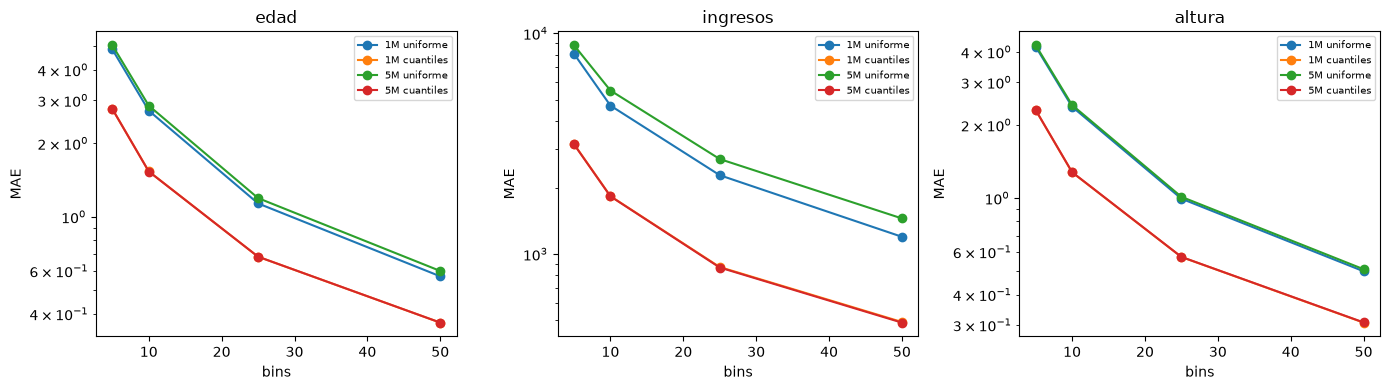

In [7]:
import matplotlib.pyplot as plt
(BASE / "graficos").mkdir(parents=True, exist_ok=True)
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(ejes, COLS):
    for ds, r in (("1M", r1), ("5M", r5)):
        for estr in ESTRATEGIAS:
            s = r[(r["columna"] == c) & (r["estrategia"] == estr) & (r["representante"] == "media")]
            ax.plot(s["bins_solicitados"], s["mae"], marker="o", label=f"{ds} {estr}")
    ax.set_title(c); ax.set_xlabel("bins"); ax.set_ylabel("MAE"); ax.set_yscale("log"); ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(BASE / "graficos" / "mae_vs_bins_1M_5M.png", dpi=130)